Discretización: M ü + A u = f(t), con n = N+1 incógnitas (N nodos interiores + el nodo libre en x = L).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

L  = 1.0      # longitud de la cuerda [m]
T  = 25.0     # tensión [N]
mu = 5.0      # densidad lineal [kg/m]
F0 = 0.1     # amplitud de la fuerza en x = L [N]

N   = 50      # nodos interiores (el nodo libre x = L es una incógnita más)
CFL = 0.9     # número de Courant para la integración temporal (debe ser <= 1)

v = np.sqrt(T/mu)   # velocidad de onda [m/s]
print(f"v = {v:.4f} m/s | F0/T = {F0/T:.1e} )")
print(f"omega_1 analitica = {np.pi*v/(2*L):.4f} rad/s")

v = 2.2361 m/s | F0/T = 4.0e-03 )
omega_1 analitica = 3.5124 rad/s


A es la matriz de rigidez y M la de masa (secciones 3.1 a 3.4 del documento). El último nodo es el extremo libre: elemento diagonal 1 en A y media masa en M.

In [ ]:
def construir_matrices(L, T, mu, N):
    """Devuelve dx, posiciones x (N+2 nodos con x0=0), A, M y el vector e_{N+1}."""
    n  = N + 1                    # incógnitas: nodos 1..N+1
    dx = L/(N + 1)
    x  = np.linspace(0, L, N + 2)

    A = np.zeros((n, n))
    i = np.arange(n)
    A[i, i] = 2.0
    A[i[:-1], i[:-1] + 1] = -1.0
    A[i[:-1] + 1, i[:-1]] = -1.0
    A[-1, -1] = 1.0               # extremo libre
    A *= T/dx

    masas = mu*dx*np.ones(n)
    masas[-1] *= 0.5              # media celda en el extremo libre
    M = np.diag(masas)

    e = np.zeros(n)
    e[-1] = 1.0                   # la fuerza actúa solo en el nodo libre
    return dx, x, A, M, e

dx, x, A, M, e = construir_matrices(L, T, mu, N)
print(f"dx = {dx:.5f} m | A y M de tamaño {A.shape}")
print("A simétrica:", np.allclose(A, A.T))

dx = 0.01961 m | A y M de tamaño (51, 51)
A simétrica: True


## Bloque 3. Método de Jacobi
Es el método del caso 2, escrito como función. Las rotaciones se aplican solo a las filas y columnas p y q (equivale a C = QᵀCQ, V = VQ).

In [ ]:
def jacobi(C, tol=1e-10, max_iter=None):
    """Autovalores y autovectores de una matriz simétrica por rotaciones de Jacobi.
    Devuelve (lambdas, V, iteraciones); los autovectores son las columnas de V."""
    C = C.copy()
    n = C.shape[0]
    V = np.eye(n)
    if max_iter is None:
        max_iter = 50*n*n
    umbral = tol*np.linalg.norm(C)
    iu = np.triu_indices(n, 1)

    for k in range(max_iter):
        fuera = np.abs(C[iu])                 # elementos fuera de la diagonal
        idx = np.argmax(fuera)
        if fuera[idx] < umbral:               # convergencia
            return np.diag(C).copy(), V, k
        p, q = iu[0][idx], iu[1][idx]

        theta = 0.5*np.arctan2(2*C[p, q], C[p, p] - C[q, q])
        c, s = np.cos(theta), np.sin(theta)

        # C <- C Q (columnas p, q)
        cp, cq = C[:, p].copy(), C[:, q].copy()
        C[:, p] = c*cp + s*cq
        C[:, q] = -s*cp + c*cq
        # C <- Q^T C (filas p, q)
        rp, rq = C[p, :].copy(), C[q, :].copy()
        C[p, :] = c*rp + s*rq
        C[q, :] = -s*rp + c*rq
        # V <- V Q
        vp, vq = V[:, p].copy(), V[:, q].copy()
        V[:, p] = c*vp + s*vq
        V[:, q] = -s*vp + c*vq

    raise RuntimeError("Jacobi no convergió: aumente max_iter")

# Prueba rápida contra numpy
lam_test, _, it = jacobi(np.array([[2., -1., 0.], [-1., 2., -1.], [0., -1., 2.]]))
print("Jacobi 3x3:", np.sort(lam_test), "| numpy:", np.linalg.eigvalsh(np.array([[2., -1., 0.], [-1., 2., -1.], [0., -1., 2.]])), f"| {it} rotaciones")

Jacobi 3x3: [0.58578644 2.         3.41421356] | numpy: [0.58578644 2.         3.41421356] | 9 rotaciones


## Bloque 4. Frecuencias naturales (Objetivo 3, paso 3 y Actividad 1)
Problema generalizado A φ = λ M φ con λ = ω². Se transforma con D = M^(−1/2) a C = D A D, se resuelve con Jacobi y se recuperan los modos como φ = D y. Se compara con la fórmula analítica y con la fórmula exacta del esquema discreto.



In [ ]:
def frecuencias_naturales(A, M, tol=1e-10):
    """Frecuencias angulares [rad/s] y modos (columnas, máximo = 1, con u0 = 0 añadido)."""
    D = np.diag(1/np.sqrt(np.diag(M)))
    C = D @ A @ D
    lam, Y, it = jacobi(C, tol)

    orden = np.argsort(lam)
    lam, Y = lam[orden], Y[:, orden]
    omega = np.sqrt(lam)

    Phi = D @ Y
    Phi = Phi/Phi[-1, :]                       # signo y escala: valor 1 en el extremo libre
    Phi = Phi/np.max(np.abs(Phi), axis=0)*np.sign(Phi[-1, :])
    Phi_completo = np.vstack([np.zeros(Phi.shape[1]), Phi])   # añade u0 = 0
    return omega, Phi_completo, it

omega_num, Phi, it = frecuencias_naturales(A, M)

nmodos = 5
n_ = np.arange(1, nmodos + 1)
omega_an   = (2*n_ - 1)*np.pi*v/(2*L)
omega_disc = 2*v/dx*np.sin((2*n_ - 1)*np.pi*dx/(4*L))   # solución exacta del esquema discreto

print(f"Jacobi: {it} rotaciones\n")
print(" n | omega Jacobi | omega disc.exacta | omega analitica | f [Hz]  | error vs analitica [%]")
for k in range(nmodos):
    err = abs(omega_num[k] - omega_an[k])/omega_an[k]*100
    print(f"{k+1:2d} | {omega_num[k]:12.5f} | {omega_disc[k]:17.5f} | {omega_an[k]:15.5f} | {omega_num[k]/(2*np.pi):7.4f} | {err:8.4f}")
print("\nJacobi vs formula discreta (error máx. relativo):", np.max(np.abs(omega_num[:nmodos] - omega_disc)/omega_disc))

Jacobi: 4044 rotaciones

 n | omega Jacobi | omega disc.exacta | omega analitica | f [Hz]  | error vs analitica [%]
 1 |      3.51227 |           3.51227 |         3.51241 |  0.5590 |   0.0040
 2 |     10.53347 |          10.53347 |        10.53722 |  1.6765 |   0.0356
 3 |     17.54469 |          17.54469 |        17.56204 |  2.7923 |   0.0988
 4 |     24.53926 |          24.53926 |        24.58685 |  3.9055 |   0.1936
 5 |     31.51055 |          31.51055 |        31.61167 |  5.0151 |   0.3199

Jacobi vs formula discreta (error máx. relativo): 2.3391293412088346e-14


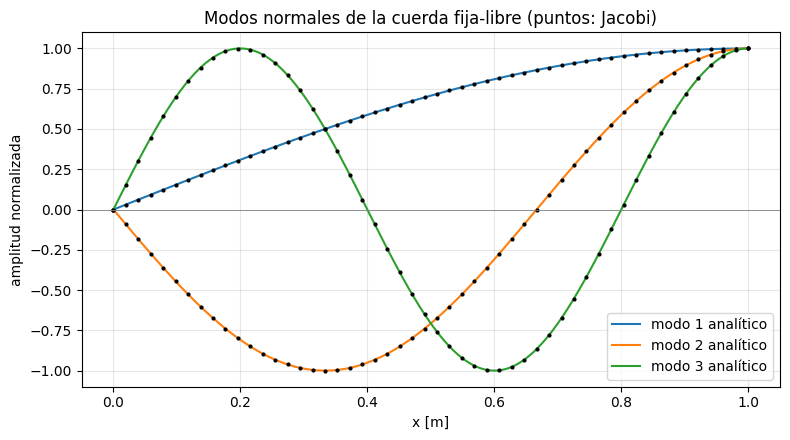

In [ ]:
# Modos normales: numérico (puntos) frente al analítico (línea)
fig, ax = plt.subplots(figsize=(8, 4.5))
xf = np.linspace(0, L, 400)
for k in range(3):
    kn = (2*(k + 1) - 1)*np.pi/(2*L)
    phi_an = np.sin(kn*xf)/np.sin(kn*L)            # normalizado a 1 en x = L
    ax.plot(xf, phi_an, lw=1.5, label=f"modo {k+1} analítico")
    ax.plot(x, Phi[:, k]/Phi[-1, k], "k.", ms=4)
ax.axhline(0, color="gray", lw=0.6)
ax.set_xlabel("x [m]"); ax.set_ylabel("amplitud normalizada")
ax.set_title("Modos normales de la cuerda fija-libre (puntos: Jacobi)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Bloque 5. Respuesta estacionaria en frecuencia (Objetivo 4)
Para una frecuencia ω, la solución particular periódica u = X cos(ωt) cumple (A − ω²M) X = F₀ e_{N+1}. Es la respuesta "sin efectos de las condiciones iniciales" (secciones 3.6 y 6.1).

In [ ]:
def respuesta_estacionaria(omega, A, M, e, F0):
    """Amplitud con signo X_j de cada nodo en el estado periódico (sin disipación)."""
    return np.linalg.solve(A - omega**2*M, F0*e)

# Comparación con la solución analítica continua X(x) = F0 sin(kx) / (T k cos(kL))
w_prueba = 5.0
k_prueba = w_prueba/v
X = respuesta_estacionaria(w_prueba, A, M, e, F0)
X_an = F0*np.sin(k_prueba*x)/(T*k_prueba*np.cos(k_prueba*L))
print(f"omega = {w_prueba} rad/s")
print(f"X(L) numérico = {X[-1]:.6e} | analítico = {X_an[-1]:.6e}")
print(f"Amplitud máxima: numérica = {np.max(np.abs(X)):.6e} | analítica = {np.max(np.abs(X_an)):.6e}")

omega = 5.0 rad/s
X(L) numérico = -2.279703e-03 | analítico = -2.279996e-03
Amplitud máxima: numérica = 2.897944e-03 | analítica = 2.897912e-03


## Bloque 6. Integración temporal (Objetivo 4)
Esquema de diferencia central (sección 5): M ü + A u = f(t), con f(t) = F₀ cos(ωt) e_{N+1}. Hay dos arranques:
- `reposo`: u(x,0) = 0 y u̇(x,0) = 0 (el problema original).
- `particular`: u(x,0) = X(ω) y u̇(x,0) = 0 (estado periódico sin transitorio).

In [ ]:
def integrar(omega, t_end, A, M, e, F0, dx, v, cfl=0.9, arranque="reposo", guardar_cada=1):
    """Integra M u'' + A u = F0 cos(omega t) e. Devuelve (t, U, dt); U[k, j] = u_j(t_k)."""
    n = len(e)
    Minv = 1.0/np.diag(M)
    f = F0*e
    dt = cfl*dx/v
    nt = int(np.ceil(t_end/dt))

    def acel(u, t):
        return Minv*(f*np.cos(omega*t) - A @ u)

    if arranque == "reposo":
        u0 = np.zeros(n)
    elif arranque == "particular":
        u0 = respuesta_estacionaria(omega, A, M, e, F0)
    else:
        raise ValueError("arranque debe ser 'reposo' o 'particular'")

    u1 = u0 + 0.5*dt**2*acel(u0, 0.0)           # primer paso de segundo orden (u_t(0) = 0)

    guardados = nt//guardar_cada + 1
    U = np.zeros((guardados, n))
    t = np.zeros(guardados)
    U[0] = u0
    u_prev, u_act = u0, u1
    g = 1
    for m in range(1, nt + 1):
        if m % guardar_cada == 0 and g < guardados:
            U[g] = u_act
            t[g] = m*dt
            g += 1
        u_sig = 2*u_act - u_prev + dt**2*acel(u_act, m*dt)
        u_prev, u_act = u_act, u_sig
    return t, U, dt

# Verificación 1: integración con arranque "particular" frente a la solución en frecuencia
w_prueba = 5.0
t_end = 3*2*np.pi/w_prueba
t, U, dt = integrar(w_prueba, t_end, A, M, e, F0, dx, v, CFL, arranque="particular")
A_tiempo = np.max(np.abs(U))
A_freq = np.max(np.abs(respuesta_estacionaria(w_prueba, A, M, e, F0)))
print(f"dt = {dt:.5f} s | amplitud en el tiempo = {A_tiempo:.6e} | en frecuencia = {A_freq:.6e}")
print(f"diferencia relativa = {abs(A_tiempo - A_freq)/A_freq:.2e}")

dt = 0.00789 s | amplitud en el tiempo = 2.899300e-03 | en frecuencia = 2.897944e-03
diferencia relativa = 4.68e-04


Resonancia: máx |u(L)| simulado = 0.33872 m | previsto = 0.34168 m


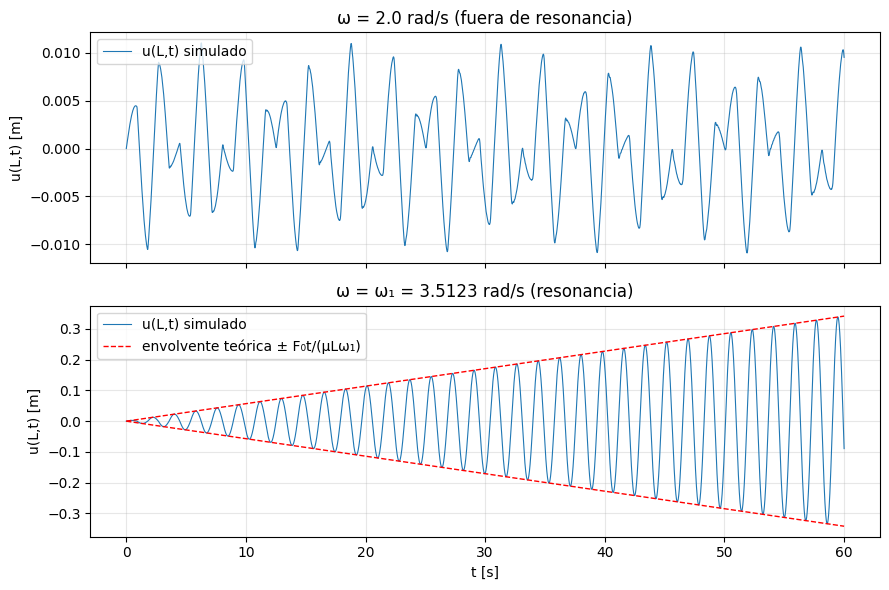

In [ ]:
# Evolución desde el reposo: fuera de resonancia (acotada) y en resonancia (crece como F0 t/(mu L omega_n))
w1 = omega_num[0]                         # primera resonancia discreta
casos = [(2.0, "ω = 2.0 rad/s (fuera de resonancia)"), (w1, f"ω = ω₁ = {w1:.4f} rad/s (resonancia)")]

fig, axs = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, (w, titulo) in zip(axs, casos):
    t, U, dt = integrar(w, 60.0, A, M, e, F0, dx, v, CFL, arranque="reposo")
    ax.plot(t, U[:, -1], lw=0.8, label="u(L,t) simulado")
    if w == w1:
        env = F0*t/(mu*L*w1)
        ax.plot(t, env, "r--", lw=1, label="envolvente teórica ± F₀t/(μLω₁)")
        ax.plot(t, -env, "r--", lw=1)
        print(f"Resonancia: máx |u(L)| simulado = {np.max(np.abs(U[:, -1])):.5f} m | previsto = {env[-1]:.5f} m")
    ax.set_title(titulo); ax.set_ylabel("u(L,t) [m]"); ax.grid(alpha=0.3); ax.legend(loc="upper left")
axs[-1].set_xlabel("t [s]")
plt.tight_layout(); plt.show()

## Bloque 7. Barrido de frecuencias y curva de amplitud (Objetivo 4 → 5)
A(ω) = máx |Xⱼ(ω)| (amplitud estacionaria). Sin disipación diverge en cada frecuencia natural, así que se grafica en escala logarítmica.

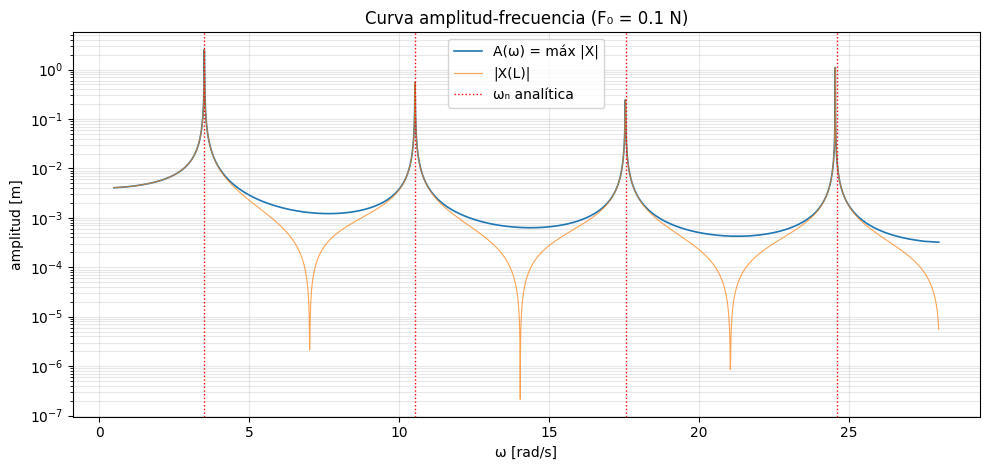

In [ ]:
omegas = np.arange(0.5, 28.0, 0.01)        # paso fino; ninguna ω cae exactamente en una resonancia
XL  = np.empty_like(omegas)                # amplitud con signo en el extremo libre
Amp = np.empty_like(omegas)                # amplitud máxima sobre todos los nodos

for i, w in enumerate(omegas):
    X = respuesta_estacionaria(w, A, M, e, F0)
    XL[i]  = X[-1]
    Amp[i] = np.max(np.abs(X))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.semilogy(omegas, Amp, lw=1.2, label="A(ω) = máx |X|")
ax.semilogy(omegas, np.abs(XL), lw=0.8, alpha=0.7, label="|X(L)|")
for n in range(1, 5):
    ax.axvline((2*n - 1)*np.pi*v/(2*L), color="r", ls=":", lw=1,
               label="ωₙ analítica" if n == 1 else None)
ax.set_xlabel("ω [rad/s]"); ax.set_ylabel("amplitud [m]")
ax.set_title("Curva amplitud-frecuencia (F₀ = %.3g N)" % F0)
ax.grid(alpha=0.3, which="both"); ax.legend(); plt.tight_layout(); plt.show()

# Bloque 8. Frecuencias resonantes (Objetivo 5)
Las resonancias son los polos de A(ω). Se usa g(ω) = 1/X(L): es suave y se anula en cada polo. Los polos corresponden a cruces de g de positivo a negativo (los ceros de X(L) dan saltos de negativo a positivo y se descartan); se refina por interpolación lineal.

In [ ]:
def detectar_resonancias(omegas, XL):
    """Frecuencias resonantes por cruce de signo (+ a -) de g = 1/X(L), con interpolación lineal."""
    with np.errstate(divide="ignore"):
        g = 1.0/XL
    idx = np.where((g[:-1] > 0) & (g[1:] < 0))[0]
    wa, wb = omegas[idx], omegas[idx + 1]
    ga, gb = g[idx], g[idx + 1]
    return wa - ga*(wb - wa)/(gb - ga)

omega_res = detectar_resonancias(omegas, XL)
nres = len(omega_res)
n_ = np.arange(1, nres + 1)
omega_an = (2*n_ - 1)*np.pi*v/(2*L)

print(" n | omega* [rad/s] | omega Jacobi | omega analitica | f* [Hz] | err vs Jacobi [%] | err vs analitica [%]")
for k in range(nres):
    e_j = abs(omega_res[k] - omega_num[k])/omega_num[k]*100
    e_a = abs(omega_res[k] - omega_an[k])/omega_an[k]*100
    print(f"{k+1:2d} | {omega_res[k]:14.5f} | {omega_num[k]:12.5f} | {omega_an[k]:15.5f} | {omega_res[k]/(2*np.pi):7.4f} | {e_j:17.5f} | {e_a:19.4f}")

 n | omega* [rad/s] | omega Jacobi | omega analitica | f* [Hz] | err vs Jacobi [%] | err vs analitica [%]
 1 |        3.51226 |      3.51227 |         3.51241 |  0.5590 |           0.00014 |              0.0041
 2 |       10.53347 |     10.53347 |        10.53722 |  1.6765 |           0.00002 |              0.0356
 3 |       17.54469 |     17.54469 |        17.56204 |  2.7923 |           0.00001 |              0.0988
 4 |       24.53926 |     24.53926 |        24.58685 |  3.9055 |           0.00000 |              0.1936


Bloque 9 (Objetivo 6): curva amplitud-frecuencia

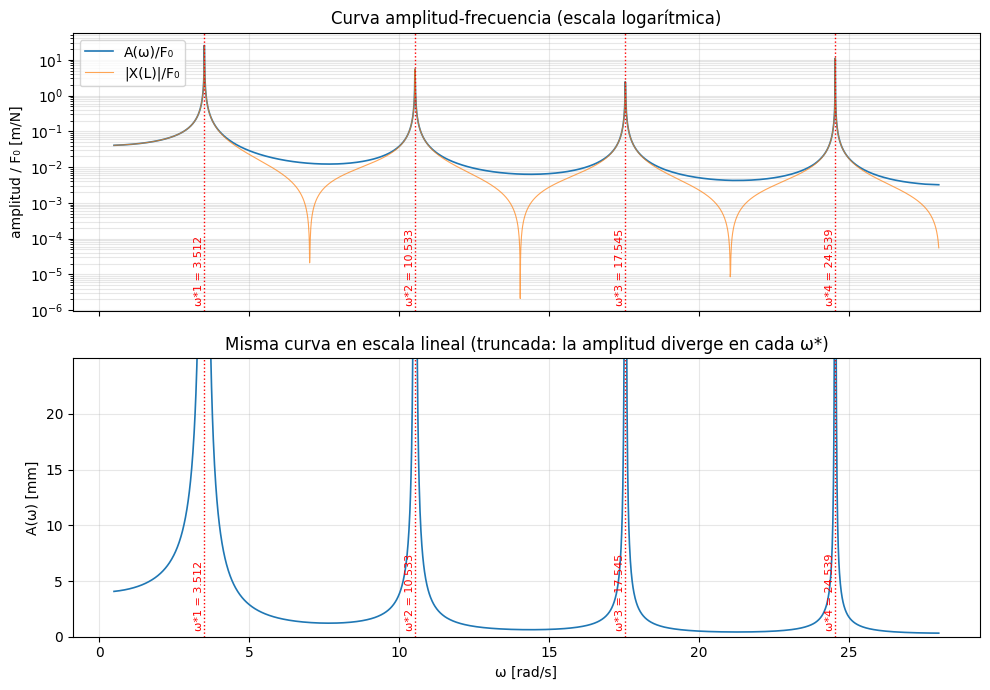

In [ ]:
omega_res = detectar_resonancias(omegas, XL)

fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax = axs[0]
ax.semilogy(omegas, Amp/F0, lw=1.2, label="A(ω)/F₀")
ax.semilogy(omegas, np.abs(XL)/F0, lw=0.8, alpha=0.7, label="|X(L)|/F₀")
ax.set_ylabel("amplitud / F₀ [m/N]")
ax.set_title("Curva amplitud-frecuencia (escala logarítmica)")

ax = axs[1]
tope = 20*np.median(Amp)*1e3                  # recorte vertical para ver la forma de los picos
ax.plot(omegas, Amp*1e3, lw=1.2)
ax.set_ylim(0, tope)
ax.set_xlabel("ω [rad/s]"); ax.set_ylabel("A(ω) [mm]")
ax.set_title("Misma curva en escala lineal (truncada: la amplitud diverge en cada ω*)")

for ax in axs:
    for k, w in enumerate(omega_res):
        ax.axvline(w, color="r", ls=":", lw=1)
        ax.text(w, 0.02, f"ω*{k+1} = {w:.3f}", transform=ax.get_xaxis_transform(),
                rotation=90, ha="right", va="bottom", color="r", fontsize=8)
    ax.grid(alpha=0.3, which="both")
axs[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

Bloque 10 (Objetivo 7): resonancias frente a frecuencias naturales\

Comparación con N = 50
 n | omega* [rad/s] | omega natural analitica | diferencia [rad/s] | error relativo [%]
 1 |        3.51226 |                 3.51241 |           -0.00014 |           0.00409
 2 |       10.53347 |                10.53722 |           -0.00375 |           0.03559
 3 |       17.54469 |                17.56204 |           -0.01735 |           0.09879

Error relativo [%] respecto a la frecuencia natural analitica
   N  |    dx    |   modo 1  |   modo 2  |   modo 3
   10 | 0.09091 |   0.08499 |   0.76296 |   2.11065
   20 | 0.04762 |   0.02342 |   0.20970 |   0.58180
   40 | 0.02439 |   0.00625 |   0.05505 |   0.15284
   80 | 0.01235 |   0.00171 |   0.01412 |   0.03918
  160 | 0.00621 |   0.00054 |   0.00359 |   0.00992

Orden observado p entre mallas consecutivas (esperado ≈ 2):
[[1.99 2.   1.99]
 [1.97 2.   2.  ]
 [1.9  2.   2.  ]
 [1.67 1.99 2.  ]]


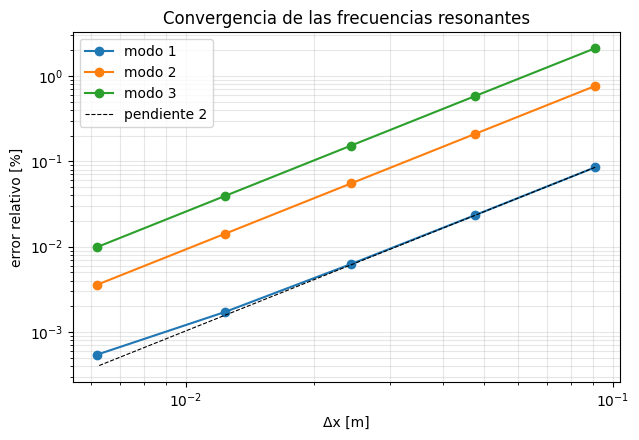

In [ ]:
def resonancias_numericas(N_, omegas_):
    """Frecuencias resonantes (barrido + cruce de g = 1/X(L)) para una malla de N_ nodos interiores."""
    dx_, _, A_, M_, e_ = construir_matrices(L, T, mu, N_)
    XL_ = np.array([np.linalg.solve(A_ - w**2*M_, F0*e_)[-1] for w in omegas_])
    return dx_, detectar_resonancias(omegas_, XL_)

# --- Comparación para la malla actual (N) ---
nres = 3
n_ = np.arange(1, nres + 1)
w_an = (2*n_ - 1)*np.pi*v/(2*L)
print(f"Comparación con N = {N}")
print(" n | omega* [rad/s] | omega natural analitica | diferencia [rad/s] | error relativo [%]")
for k in range(nres):
    dif = omega_res[k] - w_an[k]
    print(f"{k+1:2d} | {omega_res[k]:14.5f} | {w_an[k]:23.5f} | {dif:18.5f} | {abs(dif)/w_an[k]*100:17.5f}")

# --- Origen de la diferencia: refinamiento de la malla ---
Ns = [10, 20, 40, 80, 160]
omegas_c = np.arange(0.5, 20.0, 0.01)           # cubre las tres primeras resonancias
dxs, err = [], []
for N_ in Ns:
    dx_, wr = resonancias_numericas(N_, omegas_c)
    dxs.append(dx_)
    err.append(np.abs(wr[:nres] - w_an)/w_an*100)
dxs, err = np.array(dxs), np.array(err)

print("\nError relativo [%] respecto a la frecuencia natural analitica")
print("   N  |    dx    |   modo 1  |   modo 2  |   modo 3")
for i, N_ in enumerate(Ns):
    print(f"{N_:5d} | {dxs[i]:.5f} | {err[i,0]:9.5f} | {err[i,1]:9.5f} | {err[i,2]:9.5f}")
p = np.log(err[:-1]/err[1:])/np.log(dxs[:-1, None]/dxs[1:, None])
print("\nOrden observado p entre mallas consecutivas (esperado ≈ 2):")
print(np.round(p, 2))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for k in range(nres):
    ax.loglog(dxs, err[:, k], "o-", label=f"modo {k+1}")
ax.loglog(dxs, err[0, 0]*(dxs/dxs[0])**2, "k--", lw=0.8, label="pendiente 2")
ax.set_xlabel("Δx [m]"); ax.set_ylabel("error relativo [%]")
ax.set_title("Convergencia de las frecuencias resonantes")
ax.grid(alpha=0.3, which="both"); ax.legend(); plt.tight_layout(); plt.show()

Bloque 11 (Objetivo 8): evolución temporal en las tres primeras resonancias

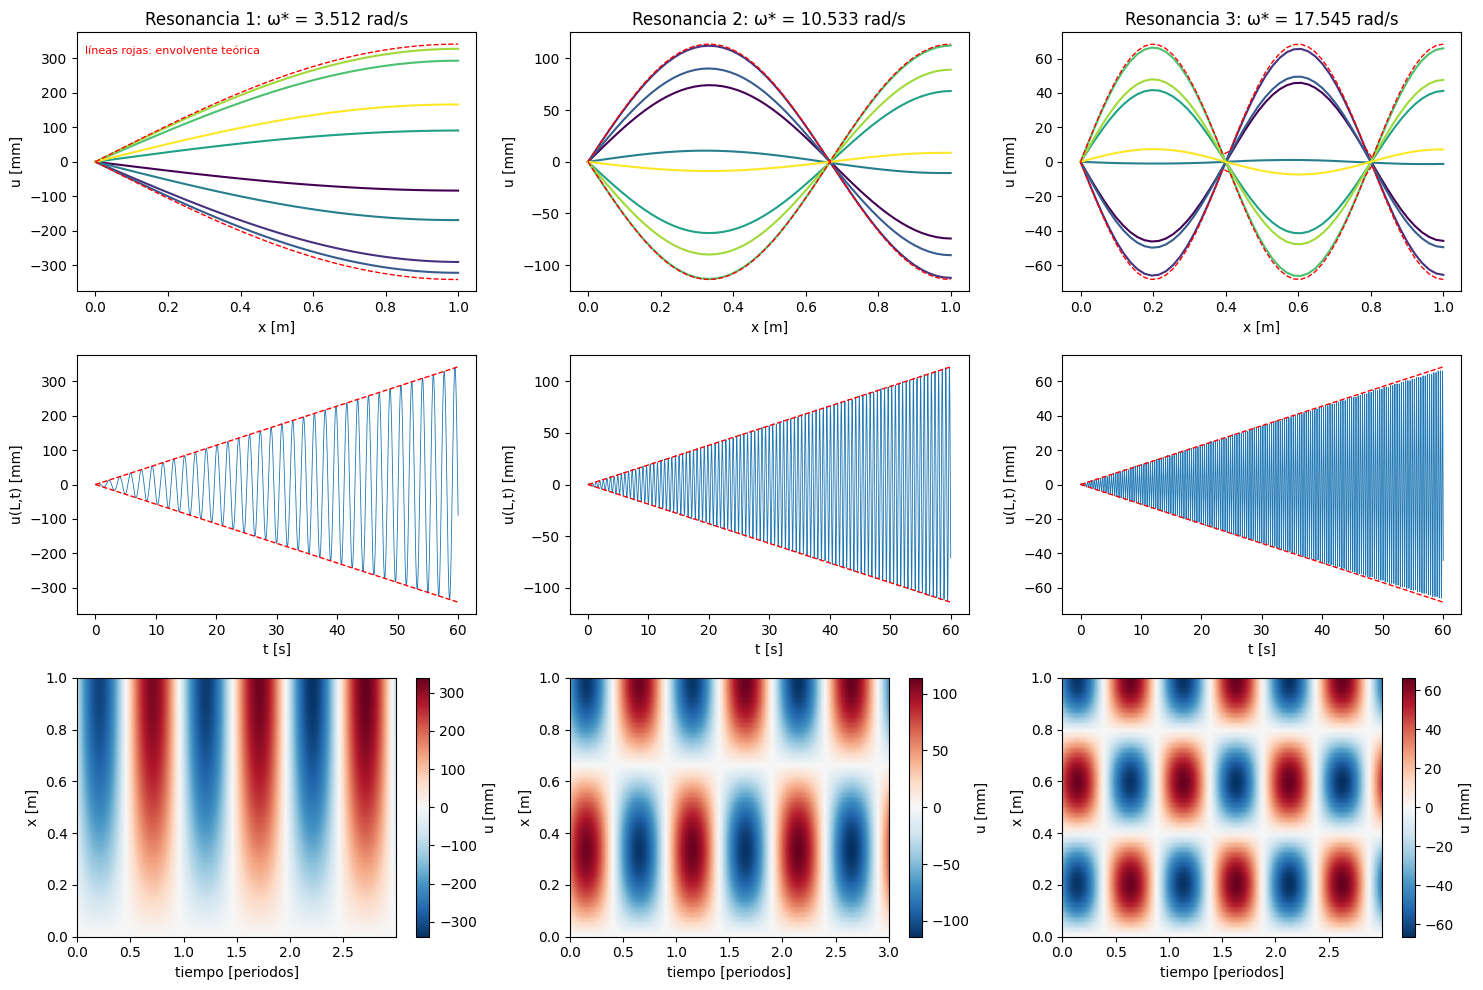

In [ ]:
def simular_resonancia(n, t_end=60.0):
    """Simula desde el reposo con ω = ω*_n. Devuelve (ω, t, U con nodo 0 incluido)."""
    w = omega_res[n - 1]
    t, U, dt = integrar(w, t_end, A, M, e, F0, dx, v, CFL, arranque="reposo")
    Uc = np.hstack([np.zeros((U.shape[0], 1)), U])        # añade u(0,t) = 0
    return w, t, Uc

t_end = 60.0
fig, axs = plt.subplots(3, 3, figsize=(15, 10))
for col, n in enumerate([1, 2, 3]):
    w, t, Uc = simular_resonancia(n, t_end)
    Tn = 2*np.pi/w
    env_L = F0*t/(mu*L*w)                                  # envolvente teórica en x = L

    # Fila 1: perfiles en 8 instantes del último periodo, dentro de la envolvente del modo n
    ax = axs[0, col]
    instantes = np.linspace(t_end - Tn, t_end, 9)[:-1]
    colores = plt.cm.viridis(np.linspace(0, 1, len(instantes)))
    for ti, c in zip(instantes, colores):
        k = np.searchsorted(t, ti)
        ax.plot(x, Uc[k]*1e3, color=c, lw=1.5)
    amp = F0*t_end/(mu*L*w)*np.abs(Phi[:, n - 1])
    ax.plot(x, amp*1e3, "r--", lw=1); ax.plot(x, -amp*1e3, "r--", lw=1)
    ax.set_title(f"Resonancia {n}: ω* = {w:.3f} rad/s")
    ax.set_xlabel("x [m]"); ax.set_ylabel("u [mm]")

    # Fila 2: evolución del extremo libre con su envolvente
    ax = axs[1, col]
    ax.plot(t, Uc[:, -1]*1e3, lw=0.6)
    ax.plot(t, env_L*1e3, "r--", lw=1); ax.plot(t, -env_L*1e3, "r--", lw=1)
    ax.set_xlabel("t [s]"); ax.set_ylabel("u(L,t) [mm]")

    # Fila 3: mapa espacio-tiempo en los últimos 3 periodos
    ax = axs[2, col]
    k0 = np.searchsorted(t, t_end - 3*Tn)
    lim = np.max(np.abs(Uc[k0:]))*1e3
    im = ax.imshow(Uc[k0:].T*1e3, aspect="auto", origin="lower", cmap="RdBu_r",
                   extent=[(t[k0] - t[k0])/Tn, (t[-1] - t[k0])/Tn, 0, L], vmin=-lim, vmax=lim)
    ax.set_xlabel("tiempo [periodos]"); ax.set_ylabel("x [m]")
    plt.colorbar(im, ax=ax, label="u [mm]")

axs[0, 0].text(0.02, 0.95, "líneas rojas: envolvente teórica", transform=axs[0, 0].transAxes,
               color="r", fontsize=8, va="top")
plt.tight_layout(); plt.show()

Bloque 12 (Objetivo 9): animaciones

Guardado: resonancia_1.gif


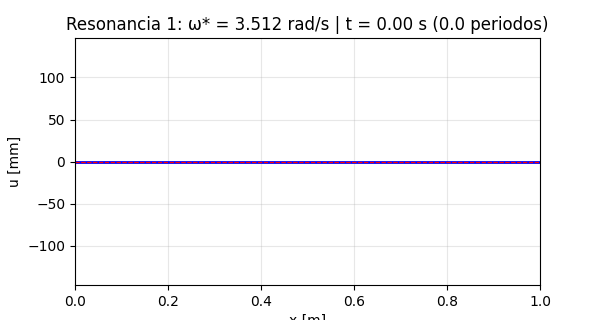

Guardado: resonancia_2.gif


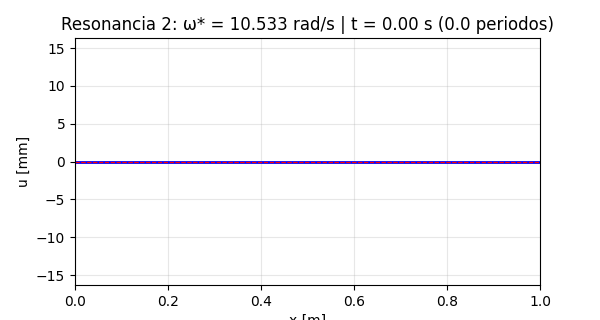

Guardado: resonancia_3.gif


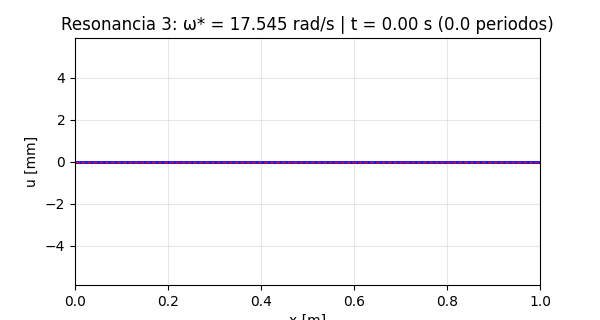

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

def animar_resonancia(n, n_periodos=12, frames_por_periodo=16, fps=15):
    """Anima la cuerda forzada en la resonancia n (desde el reposo) y guarda un GIF."""
    w = omega_res[n - 1]
    Tn = 2*np.pi/w
    dt = CFL*dx/v
    gc = max(1, int(round(Tn/dt/frames_por_periodo)))     # pasos entre cuadros guardados
    t, U, _ = integrar(w, n_periodos*Tn, A, M, e, F0, dx, v, CFL, "reposo", guardar_cada=gc)
    Uc = np.hstack([np.zeros((U.shape[0], 1)), U])*1e3     # en mm, con u(0,t) = 0

    amp_fin = F0*t[-1]/(mu*L*w)*1e3
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.set_xlim(0, L); ax.set_ylim(-1.2*amp_fin, 1.2*amp_fin)
    ax.set_xlabel("x [m]"); ax.set_ylabel("u [mm]"); ax.grid(alpha=0.3)
    linea, = ax.plot([], [], "b", lw=2)
    sup, = ax.plot([], [], "r--", lw=0.8)
    inf, = ax.plot([], [], "r--", lw=0.8)
    titulo = ax.set_title("")

    def actualizar(k):
        env = F0*t[k]/(mu*L*w)*np.abs(Phi[:, n - 1])*1e3
        linea.set_data(x, Uc[k])
        sup.set_data(x, env); inf.set_data(x, -env)
        titulo.set_text(f"Resonancia {n}: ω* = {w:.3f} rad/s | t = {t[k]:.2f} s ({t[k]/Tn:.1f} periodos)")
        return linea, sup, inf, titulo

    ani = FuncAnimation(fig, actualizar, frames=len(t), blit=False)
    archivo = f"resonancia_{n}.gif"
    ani.save(archivo, writer=PillowWriter(fps=fps))
    plt.close(fig)
    return archivo

for n in [1, 2, 3]:
    archivo = animar_resonancia(n)
    print("Guardado:", archivo)
    display(Image(filename=archivo))

Bloque 13 (Objetivo 10): energía y fase en la resonancia

 caso                           | E(60 s) [mJ] | W(60 s) [mJ] | factor de potencia cos φ
 resonancia ω = ω*₁             |    1816.6349 |    1804.4977 |      0.999
 desintonía Δ = 0.3 rad/s       |       3.9775 |       3.9775 |     -0.382
 fuera de resonancia ω = 2 rad/s |       1.3393 |       1.3480 |      0.028


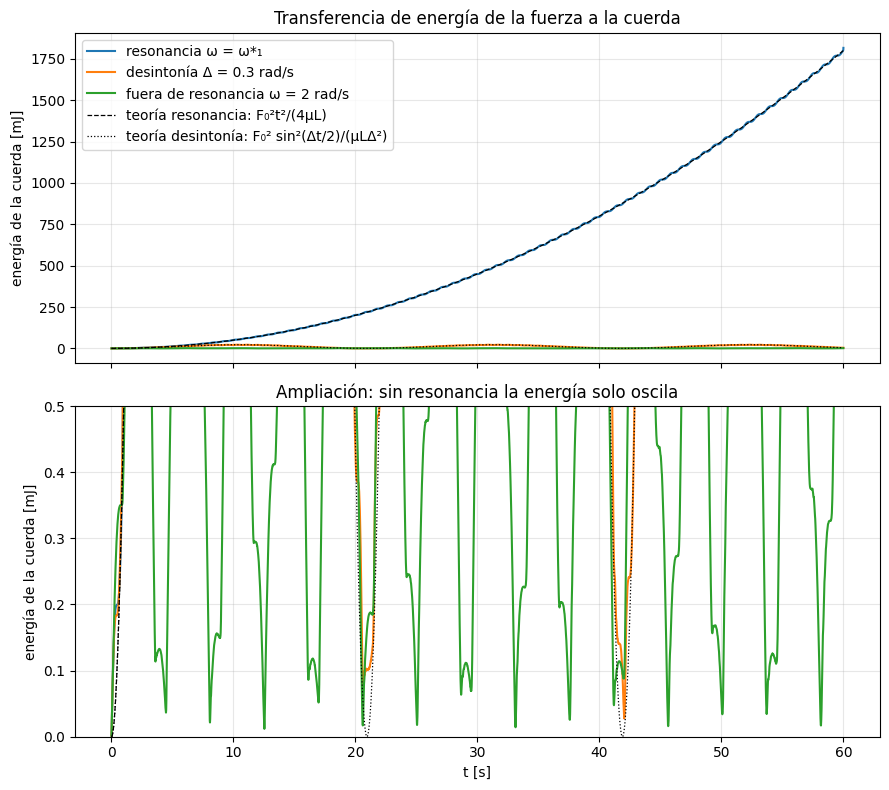

In [ ]:
def energia_y_trabajo(omega, t_end=60.0):
    """Energía de la cuerda E(t) y trabajo W(t) de la fuerza en x = L, desde el reposo."""
    t, U, dt = integrar(omega, t_end, A, M, e, F0, dx, v, CFL, "reposo", guardar_cada=1)
    Ud = np.gradient(U, dt, axis=0)                              # velocidades (diferencias centrales)
    Ecin = 0.5*np.einsum("ki,i,ki->k", Ud, np.diag(M), Ud)
    Epot = 0.5*np.einsum("ki,ij,kj->k", U, A, U)
    P = F0*np.cos(omega*t)*Ud[:, -1]                             # potencia de entrada
    W = np.concatenate([[0.0], np.cumsum(0.5*(P[1:] + P[:-1])*np.diff(t))])
    return t, Ecin + Epot, W, Ud

w1 = omega_res[0]
Delta = 0.3
casos = [(w1, "resonancia ω = ω*₁"),
         (w1 + Delta, f"desintonía Δ = {Delta} rad/s"),
         (2.0, "fuera de resonancia ω = 2 rad/s")]

fig, axs = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
print(" caso                           | E(60 s) [mJ] | W(60 s) [mJ] | factor de potencia cos φ")
for w, nombre in casos:
    t, E, W, Ud = energia_y_trabajo(w)
    for ax in axs:
        ax.plot(t, E*1e3, label=nombre)
    # cos φ = <F u'(L)> / (F_rms u'_rms) en los últimos 5 periodos de la fuerza
    ventana = t > t[-1] - 5*2*np.pi/w
    F = F0*np.cos(w*t[ventana]); uL = Ud[ventana, -1]
    cosphi = np.mean(F*uL)/(np.sqrt(np.mean(F**2))*np.sqrt(np.mean(uL**2)))
    print(f" {nombre:30s} | {E[-1]*1e3:12.4f} | {W[-1]*1e3:12.4f} | {cosphi:10.3f}")

t = np.linspace(0, 60, 2000)
for ax in axs:
    ax.plot(t, F0**2*t**2/(4*mu*L)*1e3, "k--", lw=0.9, label="teoría resonancia: F₀²t²/(4μL)")
    ax.plot(t, F0**2*np.sin(Delta*t/2)**2/(mu*L*Delta**2)*1e3, "k:", lw=0.9,
            label="teoría desintonía: F₀² sin²(Δt/2)/(μLΔ²)")
    ax.set_ylabel("energía de la cuerda [mJ]"); ax.grid(alpha=0.3)
axs[0].set_title("Transferencia de energía de la fuerza a la cuerda")
axs[0].legend(loc="upper left")
axs[1].set_ylim(0, 0.5); axs[1].set_title("Ampliación: sin resonancia la energía solo oscila")
axs[1].set_xlabel("t [s]")
plt.tight_layout(); plt.show()

Bloque 14: elección de F₀ e influencia de su amplitud (Actividades 2 y 11)

  F0 [N] | F0/T    | A(ω=5)/F0 [m/N] | máx|u(L)| a 60 s [mm] | máx|u(L)|/F0 [m/N] | pendiente máx | ¿pequeñas oscilaciones?
   0.005 | 2.0e-04 |      2.8979e-02 |                 16.94 |              3.387 |         0.027 | sí
   0.010 | 4.0e-04 |      2.8979e-02 |                 33.87 |              3.387 |         0.053 | sí
   0.020 | 8.0e-04 |      2.8979e-02 |                 67.74 |              3.387 |         0.106 | NO (modelo lineal deja de ser válido)
   0.050 | 2.0e-03 |      2.8979e-02 |                169.36 |              3.387 |         0.266 | NO (modelo lineal deja de ser válido)
   0.200 | 8.0e-03 |      2.8979e-02 |                677.44 |              3.387 |         1.062 | NO (modelo lineal deja de ser válido)


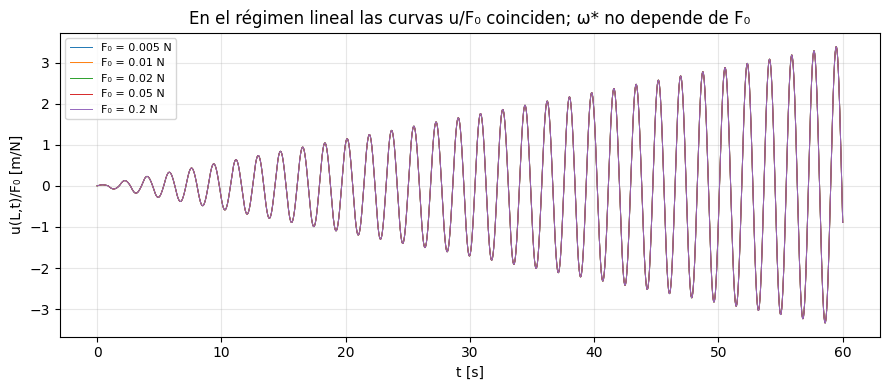

In [ ]:
w1 = omega_res[0]
F0s = [0.005, 0.01, 0.02, 0.05, 0.2]

print("  F0 [N] | F0/T    | A(ω=5)/F0 [m/N] | máx|u(L)| a 60 s [mm] | máx|u(L)|/F0 [m/N] | pendiente máx | ¿pequeñas oscilaciones?")
fig, ax = plt.subplots(figsize=(9, 4))
for F in F0s:
    X = respuesta_estacionaria(5.0, A, M, e, F)
    t, U, dt = integrar(w1, 60.0, A, M, e, F, dx, v, CFL, arranque="reposo")
    Uc = np.hstack([np.zeros((U.shape[0], 1)), U])
    pendiente = np.max(np.abs(np.diff(Uc, axis=1)))/dx
    uL = np.max(np.abs(U[:, -1]))
    ok = "sí" if pendiente < 0.1 else "NO (modelo lineal deja de ser válido)"
    print(f"{F:8.3f} | {F/T:.1e} | {np.max(np.abs(X))/F:15.4e} | {uL*1e3:21.2f} | {uL/F:18.3f} | {pendiente:13.3f} | {ok}")
    ax.plot(t, U[:, -1]/F, lw=0.7, label=f"F₀ = {F} N")
ax.set_xlabel("t [s]"); ax.set_ylabel("u(L,t)/F₀ [m/N]")
ax.set_title("En el régimen lineal las curvas u/F₀ coinciden; ω* no depende de F₀")
ax.grid(alpha=0.3); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Bloque 15: convergencia espacial (Actividad 12 y Verificación 1)

   N  |    dx    | error estacionario (máx.) | error transitorio (L2, t≈20 s)
   10 | 0.09091 |                 2.176e-03 |                      1.026e-01
   20 | 0.04762 |                 5.964e-04 |                      5.346e-02
   40 | 0.02439 |                 1.564e-04 |                      2.860e-02
   80 | 0.01235 |                 4.008e-05 |                      1.505e-02
  160 | 0.00621 |                 1.014e-05 |                      7.394e-03
Orden observado (estacionario): [2. 2. 2. 2.]
Orden observado (transitorio): [1.01 0.93 0.94 1.03]
(el transitorio converge con orden ≈ 1: la fuerza conectada de golpe genera frentes de onda con salto en ∂u/∂x)


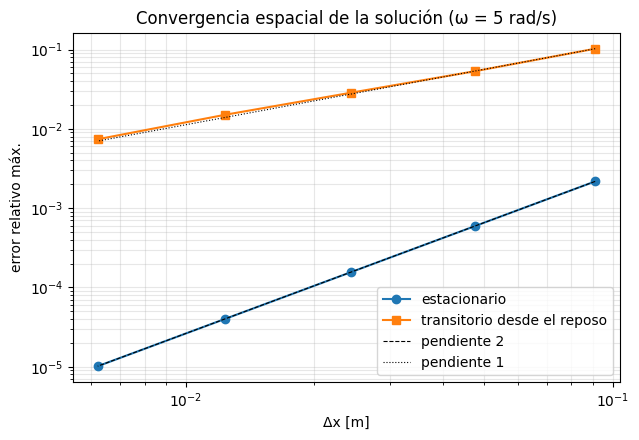

In [ ]:
def u_exacto(xs, t, omega, F0_, nmax=20000):
    """Solución analítica desde el reposo (expansión modal, sección 2.4)."""
    n = np.arange(1, nmax + 1)
    wn = (2*n - 1)*np.pi*v/(2*L)
    coef = 2*F0_*(-1.0)**(n + 1)/(mu*L)*(np.cos(omega*t) - np.cos(wn*t))/(wn**2 - omega**2)
    return np.sin(np.outer(xs, (2*n - 1)*np.pi/(2*L))) @ coef

w0, t_obj = 5.0, 20.0
Ns = [10, 20, 40, 80, 160]
filas = []
for N_ in Ns:
    dx_, x_, A_, M_, e_ = construir_matrices(L, T, mu, N_)
    # (a) solución estacionaria frente a la analítica X(x) = F0 sin(kx)/(T k cos(kL))
    X_ = respuesta_estacionaria(w0, A_, M_, e_, F0)
    k0 = w0/v
    X_an = F0*np.sin(k0*x_[1:])/(T*k0*np.cos(k0*L))
    err_est = np.max(np.abs(X_ - X_an))/np.max(np.abs(X_an))
    # (b) solución transitoria desde el reposo frente a la serie modal
    t, U, dt = integrar(w0, t_obj, A_, M_, e_, F0, dx_, v, CFL, "reposo")
    u_ex = u_exacto(x_[1:], t[-1], w0, F0)
    m_ = np.diag(M_)                                  # error en norma L2 ponderada por la masa
    err_tr = np.sqrt(np.sum(m_*(U[-1] - u_ex)**2)/np.sum(m_*u_ex**2))
    filas.append((N_, dx_, err_est, err_tr))

filas = np.array(filas)
print("   N  |    dx    | error estacionario (máx.) | error transitorio (L2, t≈20 s)")
for N_, d, a, b in filas:
    print(f"{int(N_):5d} | {d:.5f} | {a:25.3e} | {b:30.3e}")
for j, nombre in [(2, "estacionario"), (3, "transitorio")]:
    p = np.log(filas[:-1, j]/filas[1:, j])/np.log(filas[:-1, 1]/filas[1:, 1])
    print(f"Orden observado ({nombre}):", np.round(p, 2))
print("(el transitorio converge con orden ≈ 1: la fuerza conectada de golpe genera frentes de onda con salto en ∂u/∂x)")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(filas[:, 1], filas[:, 2], "o-", label="estacionario")
ax.loglog(filas[:, 1], filas[:, 3], "s-", label="transitorio desde el reposo")
ax.loglog(filas[:, 1], filas[0, 2]*(filas[:, 1]/filas[0, 1])**2, "k--", lw=0.8, label="pendiente 2")
ax.loglog(filas[:, 1], filas[0, 3]*(filas[:, 1]/filas[0, 1]), "k:", lw=0.8, label="pendiente 1")
ax.set_xlabel("Δx [m]"); ax.set_ylabel("error relativo máx.")
ax.set_title("Convergencia espacial de la solución (ω = 5 rad/s)")
ax.grid(alpha=0.3, which="both"); ax.legend(); plt.tight_layout(); plt.show()

Bloque 16: paso temporal y estabilidad (Verificación 2)

In [ ]:
w0 = 5.0
A_freq = np.max(np.abs(respuesta_estacionaria(w0, A, M, e, F0)))
cfls = [0.25, 0.5, 0.75, 0.9, 1.0, 1.02, 1.05]
print(" CFL  |    dt [s]  | error amplitud (t vs frec.) | máx|u| desde el reposo a 60 s [mm] | estable")
dts, errs = [], []
for c in cfls:
    t, U, dt = integrar(w0, 3*2*np.pi/w0, A, M, e, F0, dx, v, c, arranque="particular")
    err = abs(np.max(np.abs(U)) - A_freq)/A_freq
    with np.errstate(all="ignore"):
        t2, U2, _ = integrar(w0, 60.0, A, M, e, F0, dx, v, c, arranque="reposo", guardar_cada=50)
        m = np.max(np.abs(U2))
    estable = np.isfinite(m) and m < 1.0
    if c <= 1.0:
        dts.append(dt); errs.append(err)
    print(f"{c:5.2f} | {dt:10.6f} | {err:27.3e} | {m*1e3:35.4g} | {'sí' if estable else 'NO (CFL > 1)'}")
p = np.polyfit(np.log(dts[:-1]), np.log(errs[:-1]), 1)[0]   # CFL = 1 queda fuera: error casi nulo
print(f"\nPendiente log-log del error frente a Δt (CFL ≤ 0.9): {p:.2f} (esperado ≈ 2)")

 CFL  |    dt [s]  | error amplitud (t vs frec.) | máx|u| desde el reposo a 60 s [mm] | estable
 0.25 |   0.002192 |                   3.599e-05 |                               5.784 | sí
 0.50 |   0.004384 |                   1.487e-04 |                                5.75 | sí
 0.75 |   0.006577 |                   3.051e-04 |                               5.761 | sí
 0.90 |   0.007892 |                   4.678e-04 |                               5.799 | sí
 1.00 |   0.008769 |                   5.998e-04 |                               5.783 | sí
 1.02 |   0.008944 |                   1.001e+62 |                                 nan | NO (CFL > 1)
 1.05 |   0.009207 |                  1.252e+101 |                                 nan | NO (CFL > 1)

Pendiente log-log del error frente a Δt (CFL ≤ 0.9): 1.98 (esperado ≈ 2)


Bloque 18: tiempo total de simulación (Verificación 4)

 t_max [s] | pico de A_r [mm] | previsto F0 t/(μLω1) [mm] | ω del pico [rad/s] | 2π/t_max [rad/s]
        20 |          110.49 |                     113.89 |             3.5323 |           0.3142
        60 |          338.72 |                     341.66 |             3.5123 |           0.1047
       120 |          679.96 |                     683.32 |             3.5123 |           0.0524


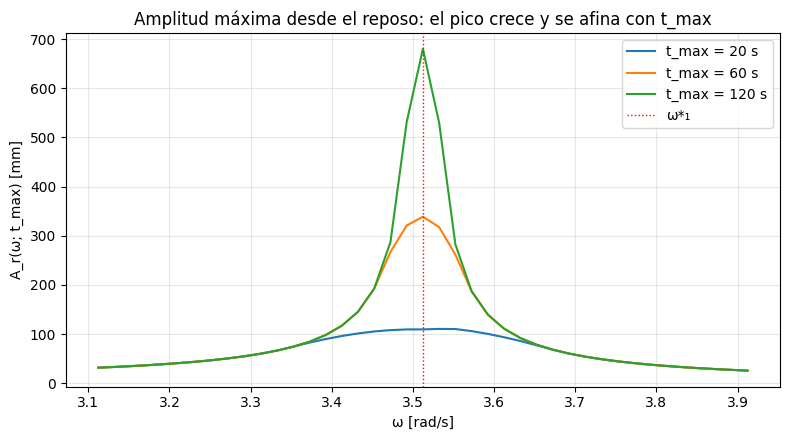


A_r(ω*₁; t_max) ∝ t_max^p con p = 1.02 (esperado 1).
La amplitud estacionaria A(ω) (bloque 5) no depende de t_max.


In [ ]:
t_maxs = [20.0, 60.0, 120.0]
w1 = omega_res[0]
omegas_loc = w1 + np.linspace(-0.4, 0.4, 41)              # entorno de la primera resonancia
Ar = np.zeros((len(t_maxs), len(omegas_loc)))
for j, w in enumerate(omegas_loc):
    t, U, dt = integrar(w, max(t_maxs), A, M, e, F0, dx, v, CFL, "reposo", guardar_cada=1)
    corrido = np.maximum.accumulate(np.max(np.abs(U), axis=1))      # máximo acumulado hasta cada t
    for i, tm in enumerate(t_maxs):
        Ar[i, j] = corrido[np.searchsorted(t, tm)]

fig, ax = plt.subplots(figsize=(8, 4.5))
print(" t_max [s] | pico de A_r [mm] | previsto F0 t/(μLω1) [mm] | ω del pico [rad/s] | 2π/t_max [rad/s]")
for i, tm in enumerate(t_maxs):
    k = np.argmax(Ar[i])
    ax.plot(omegas_loc, Ar[i]*1e3, label=f"t_max = {tm:g} s")
    print(f"{tm:10.0f} | {Ar[i, k]*1e3:15.2f} | {F0*tm/(mu*L*w1)*1e3:26.2f} | {omegas_loc[k]:18.4f} | {2*np.pi/tm:16.4f}")
ax.axvline(w1, color="r", ls=":", lw=1, label="ω*₁")
ax.set_xlabel("ω [rad/s]"); ax.set_ylabel("A_r(ω; t_max) [mm]")
ax.set_title("Amplitud máxima desde el reposo: el pico crece y se afina con t_max")
ax.grid(alpha=0.3); ax.legend(); plt.tight_layout(); plt.show()

pend = np.polyfit(np.log(t_maxs), np.log(Ar[:, len(omegas_loc)//2]), 1)[0]
print(f"\nA_r(ω*₁; t_max) ∝ t_max^p con p = {pend:.2f} (esperado 1).")
print("La amplitud estacionaria A(ω) (bloque 5) no depende de t_max.")

Bloque 19: reproducibilidad (Verificación 5)

In [ ]:
def resonancias_barrido(w_ini, w_fin, dw, invertir=False):
    ws = np.arange(w_ini, w_fin, dw)
    orden = ws[::-1] if invertir else ws
    XL_ = np.array([respuesta_estacionaria(w, A, M, e, F0)[-1] for w in orden])
    if invertir:
        XL_ = XL_[::-1]
    return detectar_resonancias(ws, XL_)[:4]

variantes = {"base (0.5, paso 0.01)": (0.5, 28.0, 0.01, False),
             "origen 0.503, paso 0.013": (0.503, 28.0, 0.013, False),
             "paso 0.004": (0.5, 28.0, 0.004, False),
             "barrido en orden inverso": (0.5, 28.0, 0.01, True)}
tabla = {nombre: resonancias_barrido(*args) for nombre, args in variantes.items()}
print(f"{'variante':28s} | " + " | ".join(f"ω*{k+1} [rad/s]" for k in range(4)))
for nombre, r in tabla.items():
    print(f"{nombre:28s} | " + " | ".join(f"{x:11.5f}" for x in r))
base = tabla["base (0.5, paso 0.01)"]
print("Diferencia máx. respecto a la base [rad/s]:", max(np.max(np.abs(r - base)) for r in tabla.values()))

# Determinismo de la integración temporal
_, U1, _ = integrar(5.0, 10.0, A, M, e, F0, dx, v, CFL, "reposo")
_, U2, _ = integrar(5.0, 10.0, A, M, e, F0, dx, v, CFL, "reposo")
print("Dos ejecuciones idénticas:", np.array_equal(U1, U2))

# Independencia respecto al número de periodos K de la ventana de medida
w0 = 5.0
for K in (1, 3, 5):
    _, U, _ = integrar(w0, K*2*np.pi/w0, A, M, e, F0, dx, v, CFL, "particular")
    print(f"K = {K}: amplitud temporal = {np.max(np.abs(U)):.6e}")

variante                     | ω*1 [rad/s] | ω*2 [rad/s] | ω*3 [rad/s] | ω*4 [rad/s]
base (0.5, paso 0.01)        |     3.51226 |    10.53347 |    17.54469 |    24.53926
origen 0.503, paso 0.013     |     3.51226 |    10.53347 |    17.54469 |    24.53926
paso 0.004                   |     3.51227 |    10.53347 |    17.54469 |    24.53926
barrido en orden inverso     |     3.51226 |    10.53347 |    17.54469 |    24.53926
Diferencia máx. respecto a la base [rad/s]: 7.020604944507625e-06
Dos ejecuciones idénticas: True
K = 1: amplitud temporal = 2.898766e-03
K = 3: amplitud temporal = 2.899300e-03
K = 5: amplitud temporal = 2.899347e-03


Bloque 20: fuentes de error (Verificación 6)

In [ ]:
n_ = np.arange(1, 4)
w_an = (2*n_ - 1)*np.pi*v/(2*L)
w_disc = 2*v/dx*np.sin((2*n_ - 1)*np.pi*dx/(4*L))
print("1) Truncamiento espacial (N = %d): error relativo [%%] =" % N, np.round(np.abs(w_disc - w_an)/w_an*100, 4))

print("2) Truncamiento temporal (frecuencia del esquema completo, modo 1):")
for c in [0.25, 0.5, 0.9, 1.0]:
    dt_ = c*dx/v
    w_t = 2/dt_*np.arcsin(w_disc[0]*dt_/2)
    print(f"   CFL = {c:4.2f}: error total vs analítica = {abs(w_t - w_an[0])/w_an[0]*100:.6f} %")

print("3) Resolución del barrido (error de ω*₁ frente a la frecuencia discreta exacta):")
for dw in [0.1, 0.05, 0.02, 0.01, 0.005]:
    r = resonancias_barrido(0.5, 28.0, dw)
    print(f"   Δω = {dw:5.3f} rad/s: {abs(r[0] - w_disc[0]):.2e} rad/s")

print("4) Tolerancia del método de Jacobi (error de ω₁ frente a la frecuencia discreta exacta):")
for tol in [1e-4, 1e-6, 1e-8, 1e-10]:
    om, _, it = frecuencias_naturales(A, M, tol)
    print(f"   tol = {tol:.0e}: {abs(om[0] - w_disc[0]):.2e} rad/s ({it} rotaciones)")

print("5) Muestreo temporal del máximo (error relativo máximo de la amplitud medida, peor fase):")
for c in [0.25, 0.9]:
    dt_ = c*dx/v
    tt = np.arange(0, 3*2*np.pi/5.0, dt_)
    peor = max(1 - np.max(np.abs(np.cos(5.0*tt + ph))) for ph in np.linspace(0, np.pi, 400))
    print(f"   CFL = {c:4.2f}: error ≈ {peor:.2e} (cota (ωΔt)²/8 = {(5.0*dt_)**2/8:.2e})")

print("6) Linealización: pendiente máxima con F0 = %.3g N → ver bloque 14 (debe ser < 0.1)." % F0)

1) Truncamiento espacial (N = 50): error relativo [%] = [0.004  0.0356 0.0988]
2) Truncamiento temporal (frecuencia del esquema completo, modo 1):
   CFL = 0.25: error total vs analítica = 0.003706 %
   CFL = 0.50: error total vs analítica = 0.002965 %
   CFL = 0.90: error total vs analítica = 0.000751 %
   CFL = 1.00: error total vs analítica = 0.000000 %
3) Resolución del barrido (error de ω*₁ frente a la frecuencia discreta exacta):
   Δω = 0.100 rad/s: 3.05e-04 rad/s
   Δω = 0.050 rad/s: 1.32e-04 rad/s
   Δω = 0.020 rad/s: 2.70e-05 rad/s
   Δω = 0.010 rad/s: 4.99e-06 rad/s
   Δω = 0.005 rad/s: 1.76e-06 rad/s
4) Tolerancia del método de Jacobi (error de ω₁ frente a la frecuencia discreta exacta):
   tol = 1e-04: 1.13e-01 rad/s (1943 rotaciones)
   tol = 1e-06: 1.30e-05 rad/s (2982 rotaciones)
   tol = 1e-08: 1.01e-10 rad/s (3585 rotaciones)
   tol = 1e-10: 8.22e-14 rad/s (4044 rotaciones)
5) Muestreo temporal del máximo (error relativo máximo de la amplitud medida, peor fase):
   CF

Bloque 21: validación (sección 1.8)

In [ ]:
import pandas as pd

n_ = np.arange(1, len(omega_res) + 1)
w_an = (2*n_ - 1)*np.pi*v/(2*L)
tabla = pd.DataFrame({
    "n": n_,
    "ω* numérica [rad/s]": omega_res,
    "f* numérica [Hz]": omega_res/(2*np.pi),
    "ω natural analítica [rad/s]": w_an,
    "f natural analítica [Hz]": w_an/(2*np.pi),
    "error relativo [%]": np.abs(omega_res - w_an)/w_an*100,
})
print(tabla.to_string(index=False, float_format=lambda z: f"{z:.5f}"))
tabla.to_csv("validacion.csv", index=False)
print("\nError máximo: %.4f %%" % tabla["error relativo [%]"].max())

 n  ω* numérica [rad/s]  f* numérica [Hz]  ω natural analítica [rad/s]  f natural analítica [Hz]  error relativo [%]
 1              3.51226           0.55899                      3.51241                   0.55902             0.00409
 2             10.53347           1.67645                     10.53722                   1.67705             0.03559
 3             17.54469           2.79232                     17.56204                   2.79508             0.09879
 4             24.53926           3.90554                     24.58685                   3.91312             0.19357

Error máximo: 0.1936 %


Bloque 22: programa modular con F₀ y ω modificables (sección 1.5, punto 10)

F0 = 0.01 N | ω = 3.5123 rad/s | resonancia más cercana = 3.5123 rad/s
máx|u| = 33.872 mm | pendiente máx = 0.053


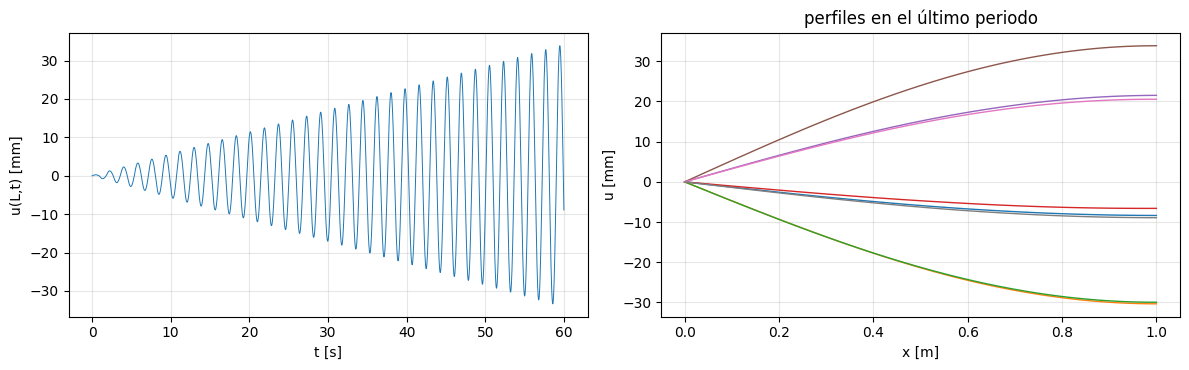

F0 = 0.01 N | ω = 6.0000 rad/s | resonancia más cercana = 3.5123 rad/s
máx|u| = 0.335 mm | pendiente máx = 0.001


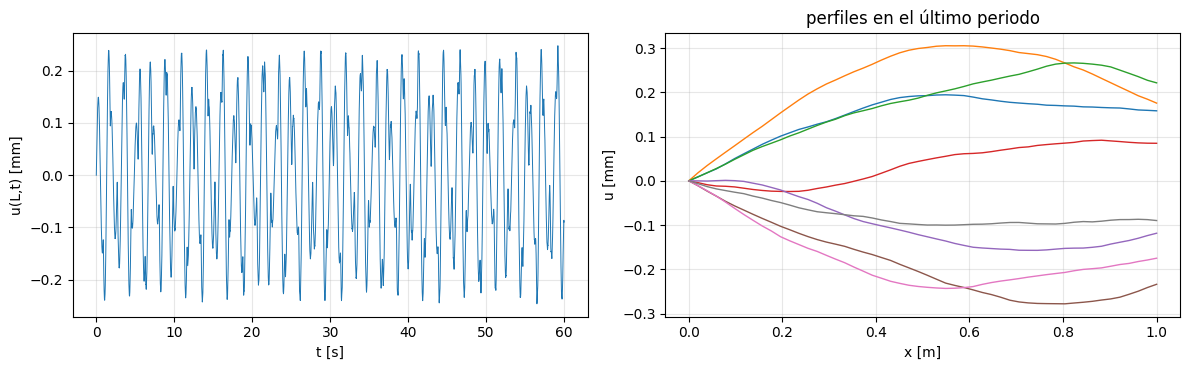

In [ ]:
def ejecutar_estudio(F0_=0.01, omega_=None, t_end=60.0, N_=50):
    """Simula la cuerda desde el reposo con la fuerza F0_ cos(omega_ t) en x = L y resume la respuesta.
    Si omega_ es None se usa la primera resonancia."""
    dx_, x_, A_, M_, e_ = construir_matrices(L, T, mu, N_)
    if omega_ is None:
        omega_ = np.sqrt(np.sort(np.linalg.eigvals(np.linalg.solve(M_, A_)).real))[0]
    t, U, dt = integrar(omega_, t_end, A_, M_, e_, F0_, dx_, v, CFL, "reposo")
    Uc = np.hstack([np.zeros((U.shape[0], 1)), U])
    resonancias = np.sqrt(np.sort(np.linalg.eigvals(np.linalg.solve(M_, A_)).real))[:4]
    cercana = resonancias[np.argmin(np.abs(resonancias - omega_))]
    print(f"F0 = {F0_} N | ω = {omega_:.4f} rad/s | resonancia más cercana = {cercana:.4f} rad/s")
    print(f"máx|u| = {np.max(np.abs(Uc))*1e3:.3f} mm | pendiente máx = {np.max(np.abs(np.diff(Uc, axis=1)))/dx_:.3f}")

    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    axs[0].plot(t, Uc[:, -1]*1e3, lw=0.7)
    axs[0].set_xlabel("t [s]"); axs[0].set_ylabel("u(L,t) [mm]"); axs[0].grid(alpha=0.3)
    k = np.searchsorted(t, t_end - 2*np.pi/omega_)
    for j in np.linspace(k, len(t) - 1, 8).astype(int):
        axs[1].plot(x_, Uc[j]*1e3, lw=1)
    axs[1].set_xlabel("x [m]"); axs[1].set_ylabel("u [mm]"); axs[1].grid(alpha=0.3)
    axs[1].set_title("perfiles en el último periodo")
    plt.tight_layout(); plt.show()
    return t, Uc

_ = ejecutar_estudio(F0_=0.01, omega_=None)    # primera resonancia
_ = ejecutar_estudio(F0_=0.01, omega_=6.0)     # fuera de resonancia

# Opcional (Colab): controles interactivos
# from ipywidgets import interact, FloatSlider
# interact(lambda F0_, omega_: ejecutar_estudio(F0_, omega_),
#          F0_=FloatSlider(min=0.001, max=0.02, step=0.001, value=0.01),
#          omega_=FloatSlider(min=0.5, max=28.0, step=0.1, value=3.5));